# Logistic Regression — Complete End-to-End Machine Learning Project

This notebook demonstrates **Logistic Regression from EDA to model saving and loading**, following a complete machine-learning workflow.

**Problem type:** Binary classification  
**Dataset:** Breast Cancer Wisconsin dataset from scikit-learn  
**Target:** `diagnosis` — malignant or benign

### Workflow
1. Import libraries and load the dataset
2. Understand and explore the data
3. Perform EDA with visualizations
4. Check data quality and outliers
5. Split data and scale features without data leakage
6. Train Logistic Regression
7. Predict and evaluate using classification metrics
8. Visualize the confusion matrix, ROC curve, sigmoid function, and coefficients
9. Predict a new sample and save/load the model

> This dataset is used for learning only; the model is not intended for medical diagnosis.

In [1]:
# 1. Import Libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_curve, roc_auc_score,
    precision_recall_curve, average_precision_score, log_loss
)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
pd.set_option("display.max_columns", None)

## 2. Load the Dataset

We use the built-in Breast Cancer Wisconsin dataset. No separate CSV download is required. The original target is encoded as `0 = malignant` and `1 = benign`; we create a readable target column for exploration.

In [2]:
# Load dataset

dataset = load_breast_cancer(as_frame=True)
X_original = dataset.data.copy()
y = dataset.target.copy()

df = X_original.copy()
df["diagnosis"] = y.map({0: "malignant", 1: "benign"})
df["target"] = y

print("Dataset loaded successfully!")
print("Shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Shape: (569, 32)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnosis,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,malignant,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,malignant,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,malignant,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,malignant,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,malignant,0


## 3. Understand the Dataset

In [3]:
# Dataset dimensions
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 569
Number of columns: 32


In [4]:
# Column names
df.columns.tolist()

['mean radius',
 'mean texture',
 'mean perimeter',
 'mean area',
 'mean smoothness',
 'mean compactness',
 'mean concavity',
 'mean concave points',
 'mean symmetry',
 'mean fractal dimension',
 'radius error',
 'texture error',
 'perimeter error',
 'area error',
 'smoothness error',
 'compactness error',
 'concavity error',
 'concave points error',
 'symmetry error',
 'fractal dimension error',
 'worst radius',
 'worst texture',
 'worst perimeter',
 'worst area',
 'worst smoothness',
 'worst compactness',
 'worst concavity',
 'worst concave points',
 'worst symmetry',
 'worst fractal dimension',
 'diagnosis',
 'target']

In [5]:
# First 10 rows
display(df.head(10))

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnosis,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,malignant,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,malignant,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,malignant,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,malignant,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,malignant,0
5,12.45,15.70,82.57,477.1,0.12780,0.17000,0.15780,0.08089,0.2087,0.07613,0.3345,0.8902,2.217,27.19,0.007510,0.03345,0.03672,0.01137,0.02165,0.005082,15.47,23.75,103.40,741.6,0.1791,0.5249,0.5355,0.1741,0.3985,0.12440,malignant,0
6,18.25,19.98,119.60,1040.0,0.09463,0.10900,0.11270,0.07400,0.1794,0.05742,0.4467,0.7732,3.180,53.91,0.004314,0.01382,0.02254,0.01039,0.01369,0.002179,22.88,27.66,153.20,1606.0,0.1442,0.2576,0.3784,0.1932,0.3063,0.08368,malignant,0
7,13.71,20.83,90.20,577.9,0.11890,0.16450,0.09366,0.05985,0.2196,0.07451,0.5835,1.3770,3.856,50.96,0.008805,0.03029,0.02488,0.01448,0.01486,0.005412,17.06,28.14,110.60,897.0,0.1654,0.3682,0.2678,0.1556,0.3196,0.11510,malignant,0
8,13.00,21.82,87.50,519.8,0.12730,0.19320,0.18590,0.09353,0.2350,0.07389,0.3063,1.0020,2.406,24.32,0.005731,0.03502,0.03553,0.01226,0.02143,0.003749,15.49,30.73,106.20,739.3,0.1703,0.5401,0.5390,0.2060,0.4378,0.10720,malignant,0
9,12.46,24.04,83.97,475.9,0.11860,0.23960,0.22730,0.08543,0.2030,0.08243,0.2976,1.5990,2.039,23.94,0.007149,0.07217,0.07743,0.01432,0.01789,0.010080,15.09,40.68,97.65,711.4,0.1853,1.0580,1.1050,0.2210,0.4366,0.20750,malignant,0


In [6]:
# Random sample
display(df.sample(5, random_state=RANDOM_STATE))

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnosis,target
204,12.47,18.60,81.09,481.9,0.09965,0.1058,0.08005,0.03821,0.1925,0.06373,0.3961,1.0440,2.497,30.29,0.006953,0.01911,0.02701,0.01037,0.01782,0.003586,14.97,24.64,96.05,677.9,0.1426,0.2378,0.2671,0.10150,0.3014,0.08750,benign,1
70,18.94,21.31,123.60,1130.0,0.09009,0.1029,0.10800,0.07951,0.1582,0.05461,0.7888,0.7975,5.486,96.05,0.004444,0.01652,0.02269,0.01370,0.01386,0.001698,24.86,26.58,165.90,1866.0,0.1193,0.2336,0.2687,0.17890,0.2551,0.06589,malignant,0
131,15.46,19.48,101.70,748.9,0.10920,0.1223,0.14660,0.08087,0.1931,0.05796,0.4743,0.7859,3.094,48.31,0.006240,0.01484,0.02813,0.01093,0.01397,0.002461,19.26,26.00,124.90,1156.0,0.1546,0.2394,0.3791,0.15140,0.2837,0.08019,malignant,0
431,12.40,17.68,81.47,467.8,0.10540,0.1316,0.07741,0.02799,0.1811,0.07102,0.1767,1.4600,2.204,15.43,0.010000,0.03295,0.04861,0.01167,0.02187,0.006005,12.88,22.91,89.61,515.8,0.1450,0.2629,0.2403,0.07370,0.2556,0.09359,benign,1
540,11.54,14.44,74.65,402.9,0.09984,0.1120,0.06737,0.02594,0.1818,0.06782,0.2784,1.7680,1.628,20.86,0.012150,0.04112,0.05553,0.01494,0.01840,0.005512,12.26,19.68,78.78,457.8,0.1345,0.2118,0.1797,0.06918,0.2329,0.08134,benign,1


In [7]:
# Dataset information
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         569 non-null

In [8]:
# Statistical summary
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
mean texture,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
mean area,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
mean compactness,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
mean concavity,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
mean concave points,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
mean symmetry,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744


In [9]:
# Data types
df.dtypes

mean radius                float64
mean texture               float64
mean perimeter             float64
mean area                  float64
mean smoothness            float64
mean compactness           float64
mean concavity             float64
mean concave points        float64
mean symmetry              float64
mean fractal dimension     float64
radius error               float64
texture error              float64
perimeter error            float64
area error                 float64
smoothness error           float64
compactness error          float64
concavity error            float64
concave points error       float64
symmetry error             float64
fractal dimension error    float64
worst radius               float64
worst texture              float64
worst perimeter            float64
worst area                 float64
worst smoothness           float64
worst compactness          float64
worst concavity            float64
worst concave points       float64
worst symmetry      

## 4. Exploratory Data Analysis (EDA)

EDA helps us understand:
- Class balance and target distribution
- Feature distributions and possible outliers
- Relationships between features
- Which features may help distinguish the two classes

In [10]:
# Check missing values
missing = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": df.isnull().mean() * 100
})
display(missing.sort_values("Missing Values", ascending=False).head(15))

,Missing Values,Missing Percentage
mean radius,0,0.0
mean texture,0,0.0
mean perimeter,0,0.0
mean area,0,0.0
mean smoothness,0,0.0
mean compactness,0,0.0
mean concavity,0,0.0
mean concave points,0,0.0
mean symmetry,0,0.0
mean fractal dimension,0,0.0


In [11]:
# Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [12]:
# Number of unique values in each column
df.nunique().sort_values().head(15)

diagnosis                   2
target                      2
worst smoothness          411
mean symmetry             432
mean radius               456
worst radius              457
mean smoothness           474
mean texture              479
worst concave points      492
symmetry error            498
mean fractal dimension    499
worst symmetry            500
concave points error      507
worst texture             511
worst perimeter           514
dtype: int64

### 4.1 Distribution of Numerical Features

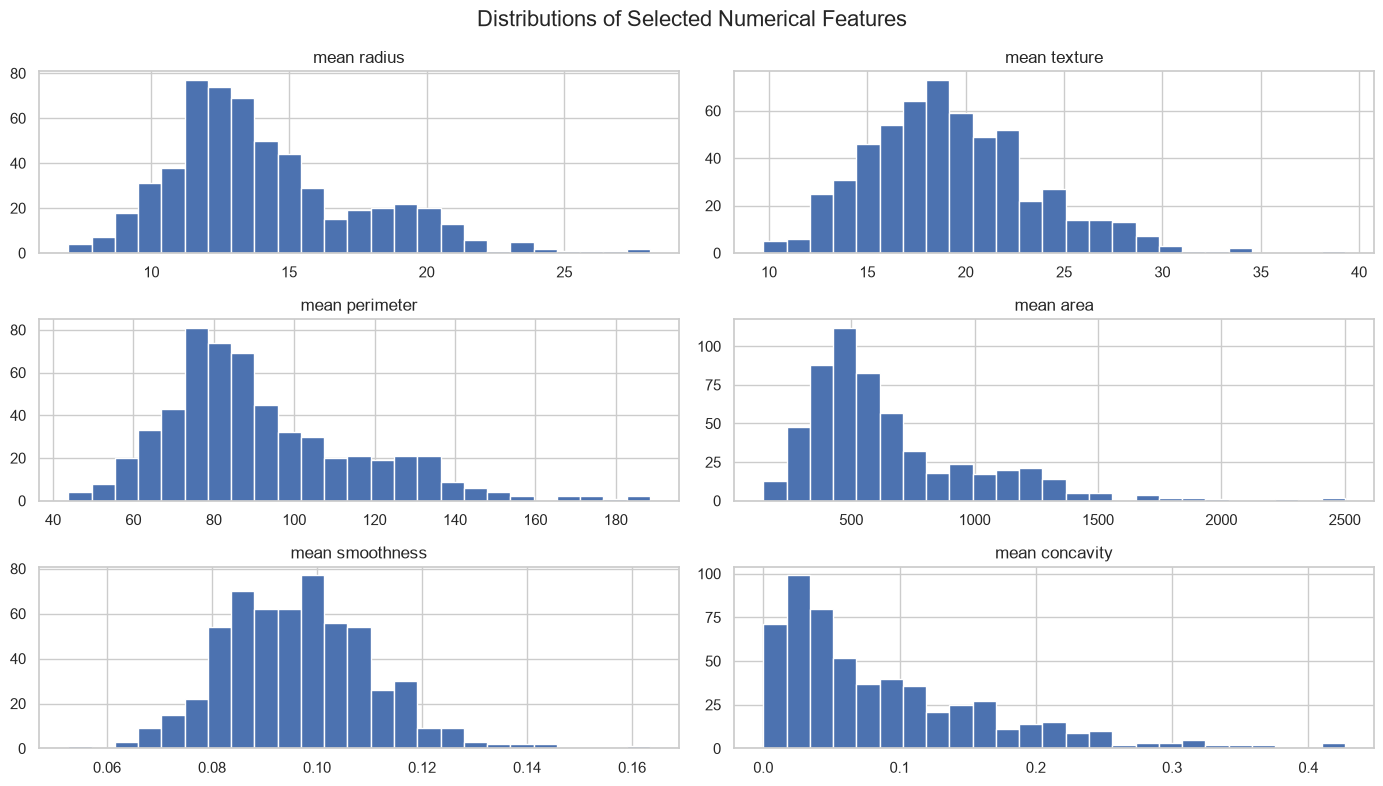

In [13]:
# Histograms for a selection of features
selected_features = ["mean radius", "mean texture", "mean perimeter",
                     "mean area", "mean smoothness", "mean concavity"]
df[selected_features].hist(figsize=(14, 8), bins=25)
plt.suptitle("Distributions of Selected Numerical Features", fontsize=16)
plt.tight_layout()
plt.show()

### 4.2 Target Variable Distribution

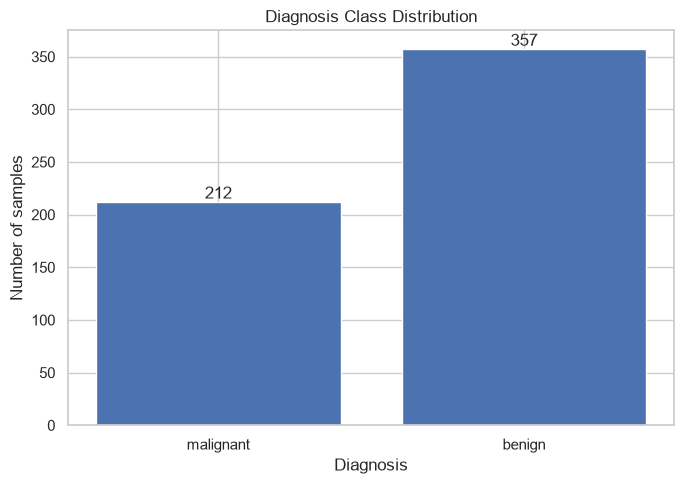

diagnosis
benign       357
malignant    212
Name: count, dtype: int64

Class proportions:


diagnosis
benign       0.627417
malignant    0.372583
Name: Proportion, dtype: float64

In [14]:
plt.figure(figsize=(7, 5))
counts = df["diagnosis"].value_counts().reindex(["malignant", "benign"])
bars = plt.bar(counts.index, counts.values)
plt.bar_label(bars)
plt.title("Diagnosis Class Distribution")
plt.xlabel("Diagnosis")
plt.ylabel("Number of samples")
plt.tight_layout()
plt.show()

print(df["diagnosis"].value_counts())
print("\nClass proportions:")
display(df["diagnosis"].value_counts(normalize=True).rename("Proportion"))

### 4.3 Boxplots — Outlier Detection

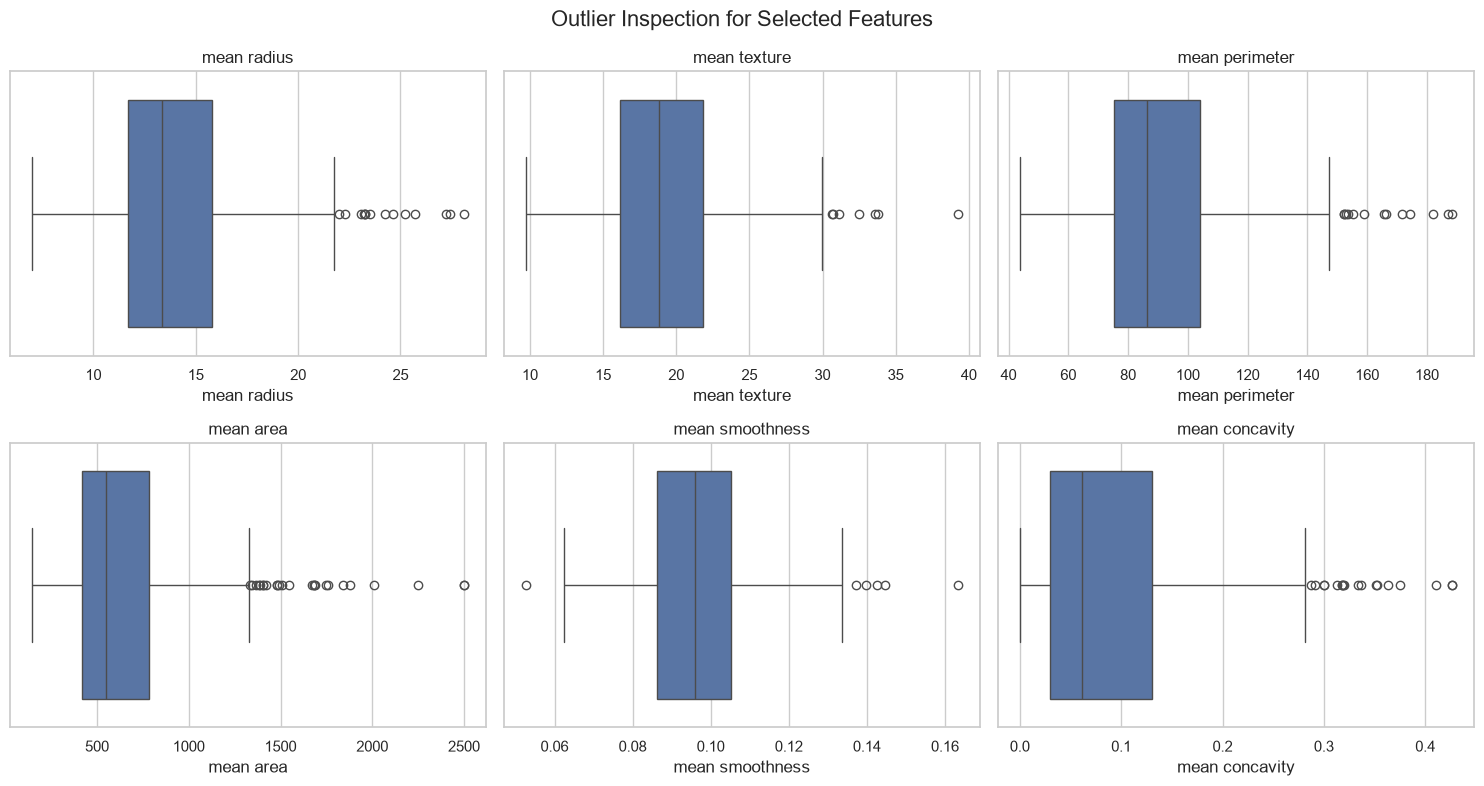

In [15]:
# Boxplots for selected features
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, feature in zip(axes.flat, selected_features):
    sns.boxplot(data=df, x=feature, ax=ax)
    ax.set_title(feature)
plt.suptitle("Outlier Inspection for Selected Features", fontsize=16)
plt.tight_layout()
plt.show()

### 4.4 Correlation Analysis

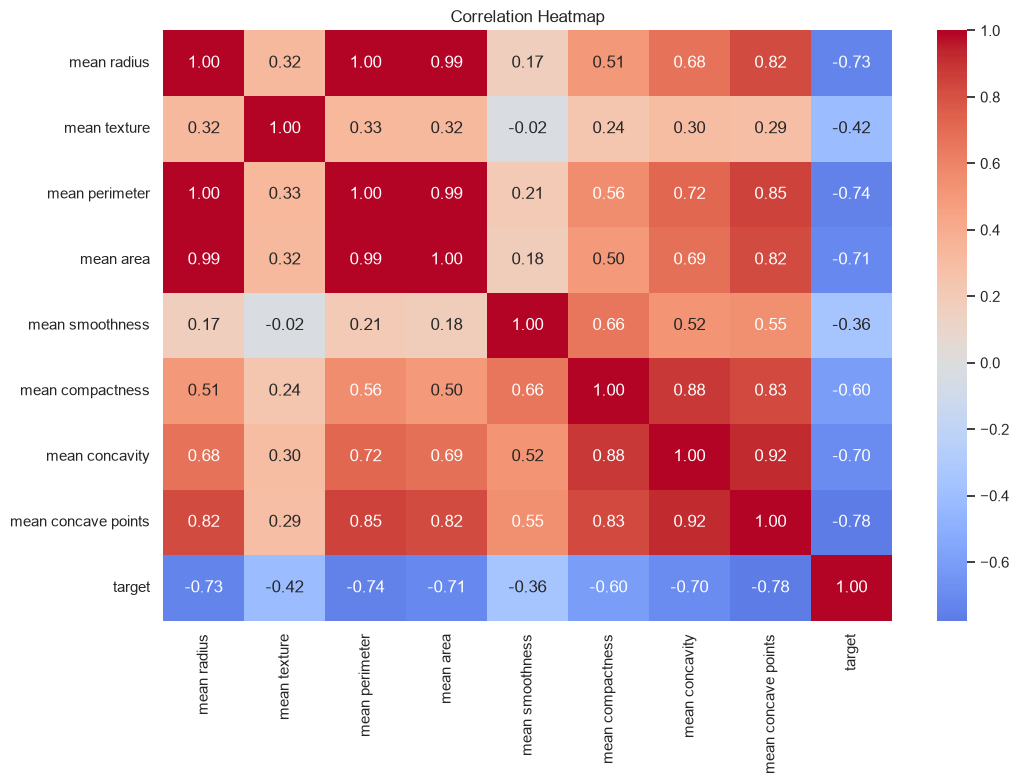

In [16]:
# Correlation heatmap for selected features
corr_features = ["mean radius", "mean texture", "mean perimeter",
                 "mean area", "mean smoothness", "mean compactness",
                 "mean concavity", "mean concave points", "target"]
plt.figure(figsize=(11, 8))
sns.heatmap(df[corr_features].corr(), annot=True, cmap="coolwarm",
            center=0, fmt=".2f")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

### 4.5 Feature vs Target Visualization

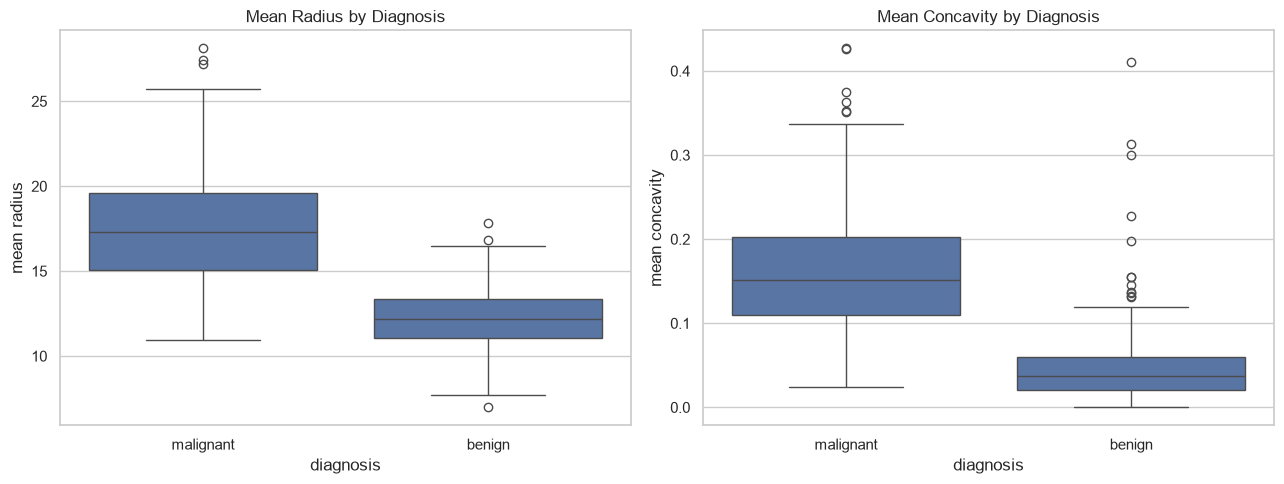

In [17]:
# Compare selected features by diagnosis
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.boxplot(data=df, x="diagnosis", y="mean radius", ax=axes[0])
axes[0].set_title("Mean Radius by Diagnosis")
sns.boxplot(data=df, x="diagnosis", y="mean concavity", ax=axes[1])
axes[1].set_title("Mean Concavity by Diagnosis")
plt.tight_layout()
plt.show()

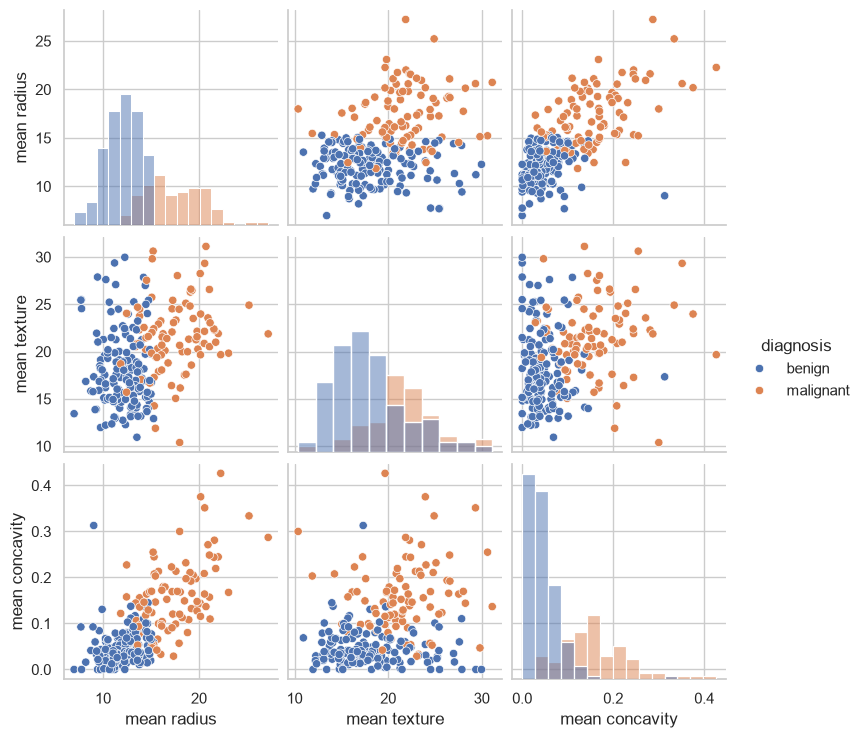

In [18]:
# Pairplot of a small feature subset
pair_df = df[["mean radius", "mean texture", "mean concavity", "diagnosis"]].sample(
    min(250, len(df)), random_state=RANDOM_STATE
)
sns.pairplot(pair_df, hue="diagnosis", diag_kind="hist")
plt.show()

## 5. Data Cleaning

Check missing values, duplicates, and invalid values. The built-in dataset is already prepared, and we do not need to impute or delete observations. We keep the full feature set for the baseline model.

In [19]:
print("Missing values in features:", X_original.isnull().sum().sum())
print("Duplicate rows in features:", X_original.duplicated().sum())
print("Any infinite values:", np.isinf(X_original.to_numpy()).any())

# Keep features and target separate
X = X_original.copy()
y = y.copy()
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Missing values in features: 0
Duplicate rows in features: 0
Any infinite values: False
Features shape: (569, 30)
Target shape: (569,)


## 6. Outlier Analysis Using IQR

The IQR rule flags unusually low or high values. Outliers are not automatically errors; in this dataset they may contain useful class information. We inspect outliers rather than removing rows blindly.

In [20]:
Q1 = X.quantile(0.25)
Q3 = X.quantile(0.75)
IQR = Q3 - Q1
outlier_counts = ((X < (Q1 - 1.5 * IQR)) | (X > (Q3 + 1.5 * IQR))).sum()

outlier_summary = outlier_counts.sort_values(ascending=False).to_frame("IQR Outlier Count")
display(outlier_summary.head(15))

,IQR Outlier Count
area error,65
radius error,38
perimeter error,38
worst area,35
smoothness error,30
fractal dimension error,28
compactness error,28
symmetry error,27
mean area,25
worst fractal dimension,24


<Figure size 1000x500 with 0 Axes>

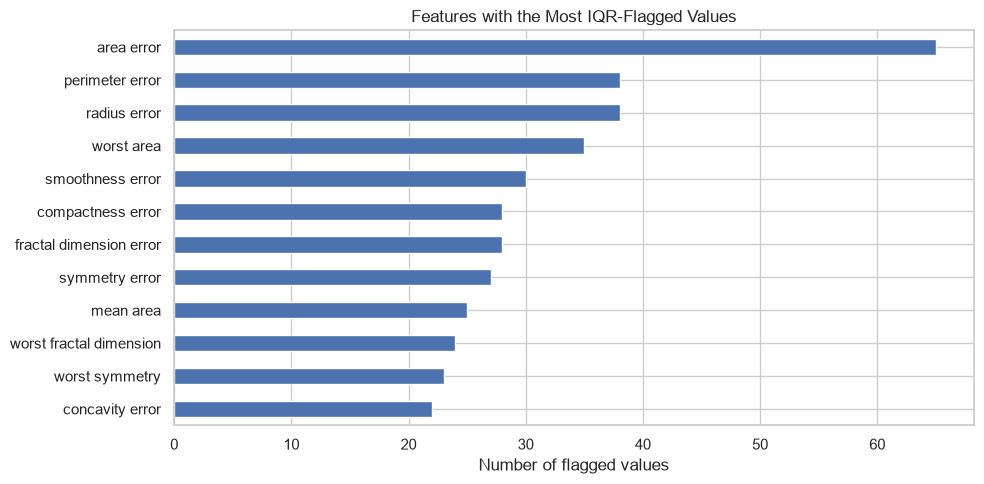

In [21]:
plt.figure(figsize=(10, 5))
outlier_summary.head(12).sort_values("IQR Outlier Count").plot(
    kind="barh", legend=False, figsize=(10, 5)
)
plt.title("Features with the Most IQR-Flagged Values")
plt.xlabel("Number of flagged values")
plt.tight_layout()
plt.show()

## 7. Separate Features and Target

In [22]:
# y: 0 = malignant, 1 = benign
X = df.drop(columns=["diagnosis", "target"])
y = df["target"].astype(int)

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Target labels:", sorted(y.unique()))

X shape: (569, 30)
y shape: (569,)
Target labels: [np.int64(0), np.int64(1)]


## 8. Train-Test Split

We keep 20% of the data for final evaluation. `stratify=y` preserves class proportions in both sets.

In [23]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("\nTraining class proportions:")
display(y_train.map({0: "malignant", 1: "benign"}).value_counts(normalize=True))
print("\nTesting class proportions:")
display(y_test.map({0: "malignant", 1: "benign"}).value_counts(normalize=True))

Training samples: 455
Testing samples: 114

Training class proportions:


target
benign       0.626374
malignant    0.373626
Name: proportion, dtype: float64


Testing class proportions:


target
benign       0.631579
malignant    0.368421
Name: proportion, dtype: float64

## 9. Feature Scaling

Logistic Regression benefits from scaling because features have different ranges. We use a `Pipeline` so the scaler is fitted only on training data and then applied to the test data, avoiding data leakage.

In [24]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaled training data shape:", X_train_scaled.shape)
print("Scaled test data shape:", X_test_scaled.shape)
print("First 5 scaled values of the first sample:")
print(X_train_scaled[0, :5])

Scaled training data shape: (455, 30)
Scaled test data shape: (114, 30)
First 5 scaled values of the first sample:
[-1.07200079 -0.6584246  -1.0880801  -0.93927364 -0.13593988]


## 10. Train Logistic Regression

Logistic Regression models the probability of class 1 using the sigmoid function. The pipeline combines standardization and the classifier.

In [25]:
model = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic_regression", LogisticRegression(
        max_iter=5000,
        C=1.0,
        random_state=RANDOM_STATE
    ))
])

model.fit(X_train, y_train)
print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [26]:
# Training and test predictions
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)
y_test_prob = model.predict_proba(X_test)[:, 1]

print("First 10 predictions:", y_test_pred[:10])
print("First 10 probabilities for class 1 (benign):")
print(np.round(y_test_prob[:10], 3))

First 10 predictions: [0 1 0 1 0 1 1 0 0 0]
First 10 probabilities for class 1 (benign):
[0.    1.    0.006 0.534 0.    0.992 1.    0.    0.    0.   ]


## 11. Model Coefficients

Coefficients are learned on standardized features. A positive coefficient pushes the prediction toward class `1` (benign), while a negative coefficient pushes it toward class `0` (malignant), holding other features constant.

In [27]:
log_reg = model.named_steps["logistic_regression"]
coef_df = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": log_reg.coef_[0]
})
coef_df["Absolute Coefficient"] = coef_df["Coefficient"].abs()
coef_df = coef_df.sort_values("Absolute Coefficient", ascending=False)

display(coef_df.head(15))

,Feature,Coefficient,Absolute Coefficient
21,worst texture,-1.255088,1.255088
10,radius error,-1.082965,1.082965
27,worst concave points,-0.953686,0.953686
23,worst area,-0.947756,0.947756
20,worst radius,-0.947616,0.947616
28,worst symmetry,-0.939181,0.939181
13,area error,-0.929104,0.929104
26,worst concavity,-0.823151,0.823151
22,worst perimeter,-0.763220,0.763220
24,worst smoothness,-0.746625,0.746625


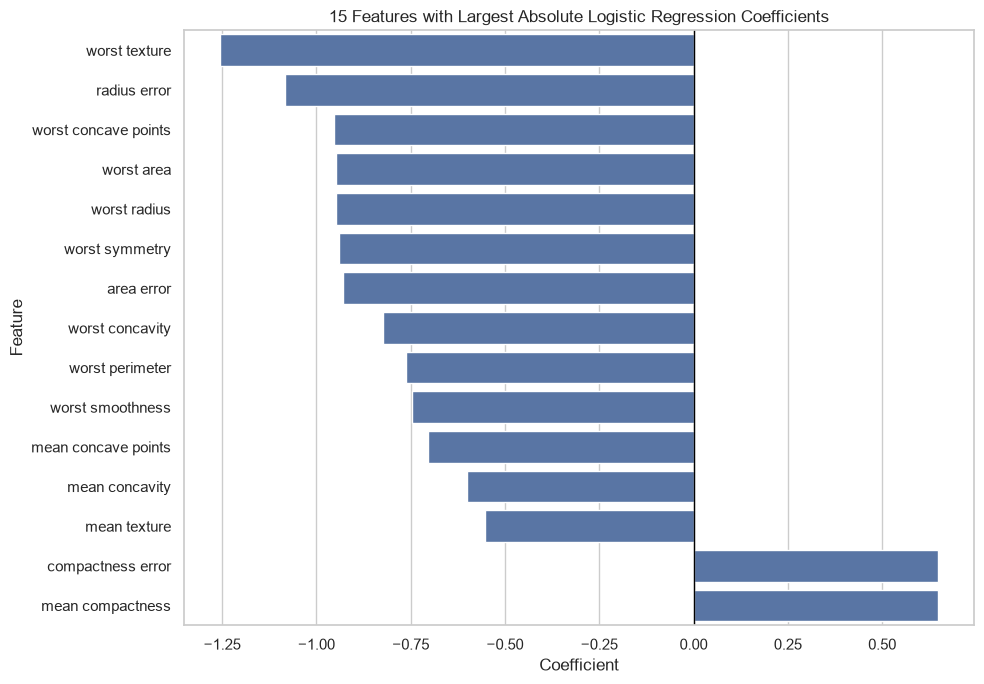

In [28]:
top_coef = coef_df.head(15).sort_values("Coefficient")
plt.figure(figsize=(10, 7))
sns.barplot(data=top_coef, x="Coefficient", y="Feature")
plt.axvline(0, color="black", linewidth=1)
plt.title("15 Features with Largest Absolute Logistic Regression Coefficients")
plt.tight_layout()
plt.show()

## 12. Make Predictions

In [29]:
# Show actual labels, predicted labels, and predicted probabilities
results = pd.DataFrame({
    "Actual": y_test.map({0: "malignant", 1: "benign"}).values,
    "Predicted": pd.Series(y_test_pred, index=y_test.index).map(
        {0: "malignant", 1: "benign"}
    ).values,
    "Probability_Benign": y_test_prob
}, index=y_test.index)

display(results.head(15))

,Actual,Predicted,Probability_Benign
256,malignant,malignant,5.888242e-08
428,benign,benign,9.999887e-01
501,malignant,malignant,6.410825e-03
363,benign,benign,5.335085e-01
564,malignant,malignant,6.525001e-10
464,benign,benign,9.921604e-01
358,benign,benign,9.999828e-01
343,malignant,malignant,5.635275e-07
516,malignant,malignant,5.431637e-05
567,malignant,malignant,8.041849e-11


## 13. Performance Metrics

We evaluate several metrics because accuracy alone may hide important classification errors. Here class `1` (benign) is treated as the positive class for precision and recall.

In [30]:
metrics = {
    "Accuracy": accuracy_score(y_test, y_test_pred),
    "Precision (benign)": precision_score(y_test, y_test_pred, zero_division=0),
    "Recall (benign)": recall_score(y_test, y_test_pred, zero_division=0),
    "F1-score (benign)": f1_score(y_test, y_test_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_test_prob),
    "Average Precision": average_precision_score(y_test, y_test_prob),
    "Log Loss": log_loss(y_test, model.predict_proba(X_test))
}
metrics_df = pd.DataFrame(list(metrics.items()), columns=["Metric", "Score"])
display(metrics_df.style.format({"Score": "{:.4f}"}))

,Metric,Score
0,Accuracy,0.9825
1,Precision (benign),0.9861
2,Recall (benign),0.9861
3,F1-score (benign),0.9861
4,ROC-AUC,0.9954
5,Average Precision,0.9971
6,Log Loss,0.0777


In [31]:
print(classification_report(
    y_test, y_test_pred,
    labels=[0, 1],
    target_names=["Malignant", "Benign"],
    zero_division=0
))

              precision    recall  f1-score   support

   Malignant       0.98      0.98      0.98        42
      Benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



## 14. Confusion Matrix Visualization

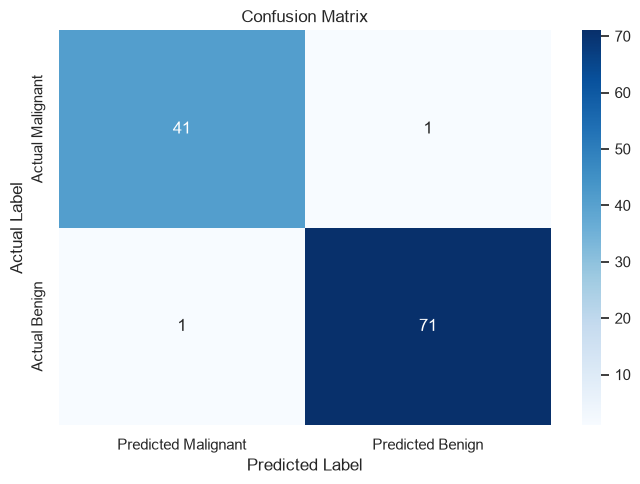

TN=41, FP=1, FN=1, TP=71


In [32]:
cm = confusion_matrix(y_test, y_test_pred, labels=[0, 1])
plt.figure(figsize=(7, 5))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Predicted Malignant", "Predicted Benign"],
    yticklabels=["Actual Malignant", "Actual Benign"]
)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"TN={tn}, FP={fp}, FN={fn}, TP={tp}")

## 15. ROC Curve

The ROC curve shows the true-positive rate against the false-positive rate at different probability thresholds. ROC-AUC summarizes ranking performance.

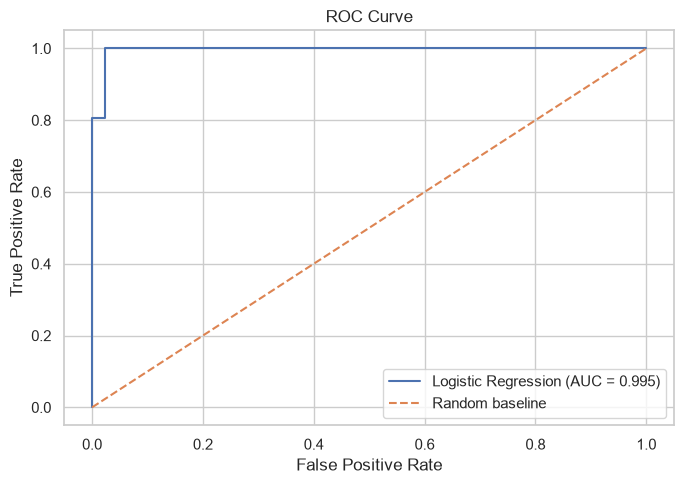

In [33]:
fpr, tpr, roc_thresholds = roc_curve(y_test, y_test_prob)
auc_value = roc_auc_score(y_test, y_test_prob)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {auc_value:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random baseline")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.tight_layout()
plt.show()

## 16. Precision-Recall Curve

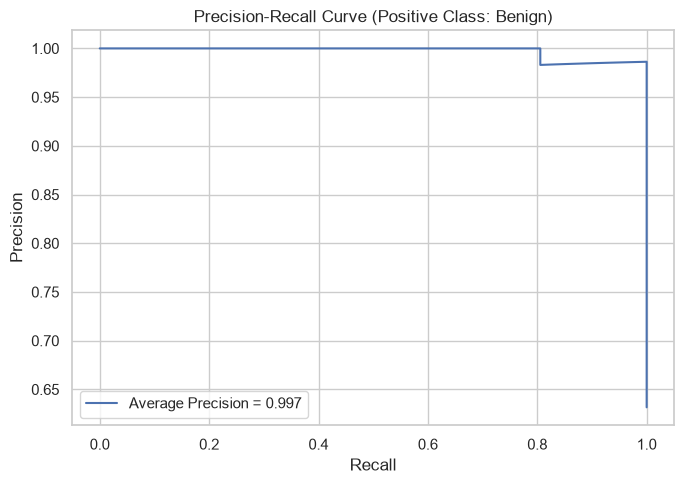

In [34]:
precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_test_prob)
ap_value = average_precision_score(y_test, y_test_prob)

plt.figure(figsize=(7, 5))
plt.plot(recall_vals, precision_vals, label=f"Average Precision = {ap_value:.3f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve (Positive Class: Benign)")
plt.legend()
plt.tight_layout()
plt.show()

## 17. Sigmoid Function Visualization

For a linear score `z = wᵀx + b`, the sigmoid maps it to a probability:

\[\sigma(z)=\frac{1}{1+e^{-z}}\]

The default decision threshold is 0.5.

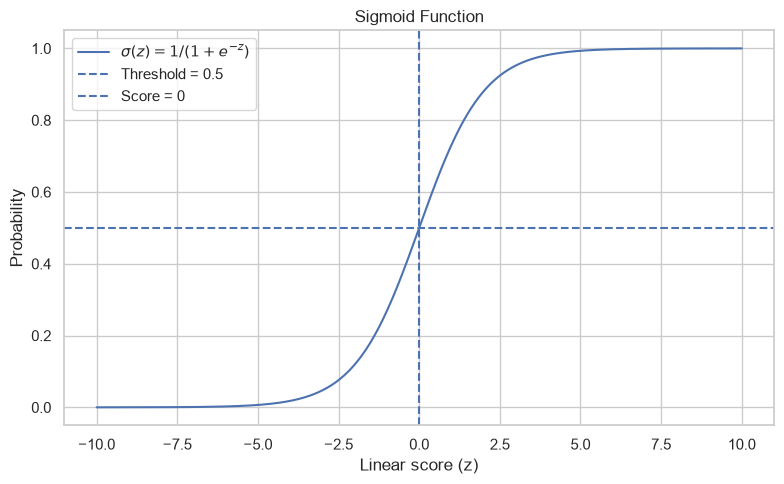

In [35]:
z = np.linspace(-10, 10, 400)
sigmoid = 1 / (1 + np.exp(-z))

plt.figure(figsize=(8, 5))
plt.plot(z, sigmoid, label=r"$\sigma(z)=1/(1+e^{-z})$")
plt.axhline(0.5, linestyle="--", label="Threshold = 0.5")
plt.axvline(0, linestyle="--", label="Score = 0")
plt.xlabel("Linear score (z)")
plt.ylabel("Probability")
plt.title("Sigmoid Function")
plt.legend()
plt.tight_layout()
plt.show()

## 18. Classification Threshold Analysis

Changing the probability threshold changes the balance between precision and recall. The threshold should be selected based on the task and the cost of different errors.

In [36]:
thresholds_to_try = [0.3, 0.4, 0.5, 0.6, 0.7]
threshold_rows = []
for threshold in thresholds_to_try:
    pred_at_threshold = (y_test_prob >= threshold).astype(int)
    threshold_rows.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, pred_at_threshold),
        "Precision": precision_score(y_test, pred_at_threshold, zero_division=0),
        "Recall": recall_score(y_test, pred_at_threshold, zero_division=0),
        "F1-score": f1_score(y_test, pred_at_threshold, zero_division=0)
    })

threshold_df = pd.DataFrame(threshold_rows)
display(threshold_df.round(4))

,Threshold,Accuracy,Precision,Recall,F1-score
0,0.3,0.9825,0.9730,1.0000,0.9863
1,0.4,0.9825,0.9861,0.9861,0.9861
2,0.5,0.9825,0.9861,0.9861,0.9861
3,0.6,0.9561,0.9855,0.9444,0.9645
4,0.7,0.9474,0.9853,0.9306,0.9571


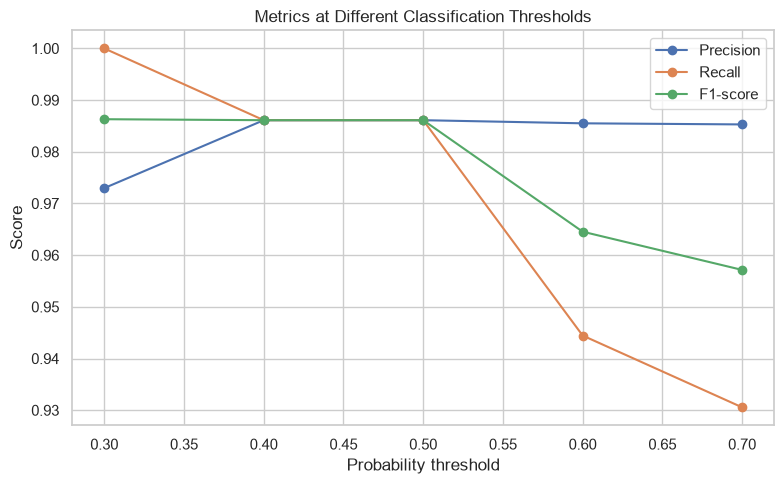

In [37]:
plt.figure(figsize=(8, 5))
for metric_name in ["Precision", "Recall", "F1-score"]:
    plt.plot(threshold_df["Threshold"], threshold_df[metric_name],
             marker="o", label=metric_name)
plt.xlabel("Probability threshold")
plt.ylabel("Score")
plt.title("Metrics at Different Classification Thresholds")
plt.legend()
plt.tight_layout()
plt.show()

## 19. Training vs Testing Performance

Comparing training and test scores can help identify potential overfitting. These scores are a quick diagnostic, not a replacement for cross-validation.

In [38]:
train_prob = model.predict_proba(X_train)[:, 1]
performance_comparison = pd.DataFrame({
    "Dataset": ["Training", "Testing"],
    "Accuracy": [
        accuracy_score(y_train, y_train_pred),
        accuracy_score(y_test, y_test_pred)
    ],
    "ROC-AUC": [
        roc_auc_score(y_train, train_prob),
        roc_auc_score(y_test, y_test_prob)
    ]
})
display(performance_comparison.round(4))

,Dataset,Accuracy,ROC-AUC
0,Training,0.9890,0.9975
1,Testing,0.9825,0.9954


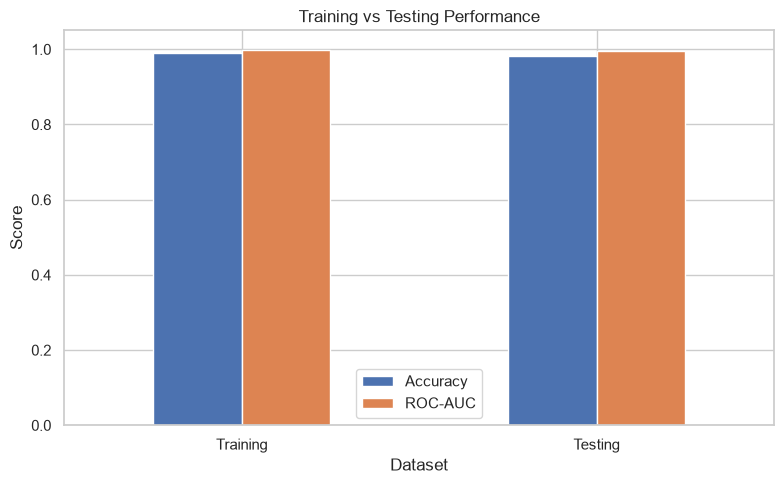

In [39]:
performance_comparison.set_index("Dataset")[["Accuracy", "ROC-AUC"]].plot(
    kind="bar", figsize=(8, 5), ylim=(0, 1.05)
)
plt.title("Training vs Testing Performance")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 20. Prediction on a New Sample

Use one feature row from the dataset to demonstrate the prediction API. This is an example input, not a medical assessment.

In [40]:
sample = X_test.iloc[[0]]
sample_prediction = model.predict(sample)[0]
sample_probabilities = model.predict_proba(sample)[0]

print("Predicted class:", "Benign" if sample_prediction == 1 else "Malignant")
print(f"Probability malignant: {sample_probabilities[0]:.4f}")
print(f"Probability benign:    {sample_probabilities[1]:.4f}")
print("Actual class:", "Benign" if y_test.iloc[0] == 1 else "Malignant")

Predicted class: Malignant
Probability malignant: 1.0000
Probability benign:    0.0000
Actual class: Malignant


In [41]:
# Example with a manually selected row of valid feature values
new_sample = X.iloc[[0]]
new_prediction = model.predict(new_sample)[0]
new_probabilities = model.predict_proba(new_sample)[0]

print("Predicted diagnosis:", "Benign" if new_prediction == 1 else "Malignant")
print("Class probabilities:", {
    "malignant": round(float(new_probabilities[0]), 4),
    "benign": round(float(new_probabilities[1]), 4)
})

Predicted diagnosis: Malignant
Class probabilities: {'malignant': 1.0, 'benign': 0.0}


## 21. Save the Model

We save the full pipeline, including the scaler and classifier, so future predictions use the same preprocessing.

In [42]:
model_path = "logistic_regression_pipeline.joblib"
joblib.dump(model, model_path)
print(f"Model saved to: {model_path}")

Model saved to: logistic_regression_pipeline.joblib


## 22. Load the Saved Model

In [43]:
loaded_model = joblib.load(model_path)
loaded_predictions = loaded_model.predict(X_test)

print("Loaded model accuracy:", round(accuracy_score(y_test, loaded_predictions), 4))
print("Predictions match original model:",
      np.array_equal(y_test_pred, loaded_predictions))

Loaded model accuracy: 0.9825
Predictions match original model: True


## 23. Practice Questions

1. What is the difference between Linear Regression and Logistic Regression?
2. Why does Logistic Regression use the sigmoid function?
3. Explain TP, TN, FP, and FN in the confusion matrix.
4. Why do we scale features for Logistic Regression?
5. Why should the scaler be fitted only on the training set?
6. What happens to precision and recall when the threshold changes?
7. What does ROC-AUC tell us?
8. Why can accuracy be misleading on imbalanced datasets?
9. What is the role of the regularization parameter `C`?
10. Why save the whole pipeline instead of only the classifier?

### Key Takeaways

- Logistic Regression is a **classification** algorithm despite its name.
- It estimates probabilities and converts them into classes using a threshold.
- Scaling, a proper train-test split, and multiple evaluation metrics are important.
- Threshold choice depends on the consequences of false positives and false negatives.
- The saved pipeline preserves both preprocessing and model behavior.

# Final Summary

This notebook covered the complete Logistic Regression workflow: data loading, exploration, cleaning checks, outlier inspection, train-test split, feature scaling, model training, predictions, classification metrics, confusion matrix, ROC and precision-recall curves, sigmoid visualization, threshold analysis, and model persistence.